# 9. Results at a glance

226 anonymous outlets, one split by score, 5 folds; every number is per outlet with its 95% interval (bootstrap over
outlets). Darker = better (for MAE and errors, lighter = better).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import common as C

pd.set_option("display.width", 220)
all_metrics = pd.read_csv(C.OUT / "all_metrics.csv")
intervals = pd.read_csv(C.OUT / "intervals.csv")
pairs = pd.read_csv(C.OUT / "classifier_vs_regressor.csv")


def table(space, metrics, lower_is_better=()):
    """Model × view, coloured column by column."""
    d = all_metrics[all_metrics.space == space].set_index(["model", "approach", "view"])[metrics]
    st = d.style.format("{:.3f}")
    for c in metrics:
        st = st.background_gradient(cmap="Blues_r" if c in lower_is_better else "Blues", subset=[c])
    return st


def with_intervals(space):
    d = intervals[intervals.space == space]
    d = d.assign(text=[f"{v:.3f} [{a:.3f}; {b:.3f}]" if abs(v) < 2 else f"{v:.1f} [{a:.1f}; {b:.1f}]"
                       for v, a, b in zip(d.value, d.low, d.high)])
    return d.pivot_table(index=["model", "approach", "view"], columns="metric", values="text", aggfunc="first")

## Levels

In [2]:
table("levels", ["F1 macro", "tolerant (±1 level)", "quadratic kappa", "Spearman", "reliable: accuracy", "accuracy",
                 "mean level error"], lower_is_better=["mean level error"])

In [3]:
with_intervals("levels")

metric                                                       F1 macro              Spearman       quadratic kappa    reliable: accuracy   tolerant (±1 level)
model       approach   view                                                                                                                                  
Mistral-24B classifier majority level            0.400 [0.331; 0.461]  0.599 [0.501; 0.686]  0.596 [0.491; 0.686]  0.748 [0.686; 0.805]  0.819 [0.765; 0.867]
            regressor  levels: NewsGuard bounds  0.282 [0.229; 0.337]  0.685 [0.605; 0.753]  0.621 [0.549; 0.682]  0.819 [0.765; 0.867]  0.881 [0.836; 0.920]
                       levels: article vote      0.387 [0.323; 0.447]  0.690 [0.621; 0.750]  0.693 [0.615; 0.757]  0.805 [0.752; 0.854]  0.854 [0.805; 0.898]
                       levels: training quotas   0.425 [0.354; 0.493]  0.703 [0.632; 0.761]  0.705 [0.629; 0.770]  0.814 [0.761; 0.863]  0.863 [0.814; 0.907]
ModernBERT  regressor  levels: NewsGuard bounds  0.251 [0.205; 0.295]  0.559 [0.467; 0.641]  0.499 [0.413; 0.574]  0.757 [0.699; 0.814]  0.810 [0.757; 0.858]
                       levels: article vote      0.305 [0.246; 0.362]  0.538 [0.441; 0.618]  0.544 [0.443; 0.629]  0.743 [0.686; 0.797]  0.770 [0.712; 0.823]
                       levels: training quotas   0.377 [0.314; 0.438]  0.589 [0.495; 0.674]  0.596 [0.500; 0.683]  0.761 [0.704; 0.814]  0.810 [0.757; 0.859]
Qwen3-8B    classifier majority level            0.384 [0.316; 0.446]  0.682 [0.607; 0.741]  0.671 [0.591; 0.736]  0.765 [0.708; 0.819]  0.819 [0.765; 0.867]
            regressor  levels: NewsGuard bounds  0.256 [0.214; 0.296]  0.692 [0.613; 0.755]  0.606 [0.537; 0.665]  0.827 [0.779; 0.876]  0.881 [0.836; 0.920]
                       levels: article vote      0.319 [0.262; 0.371]  0.653 [0.577; 0.718]  0.668 [0.586; 0.733]  0.796 [0.739; 0.850]  0.845 [0.796; 0.889]
                       levels: training quotas   0.411 [0.343; 0.472]  0.715 [0.650; 0.769]  0.722 [0.651; 0.781]  0.823 [0.770; 0.872]  0.881 [0.836; 0.920]
TF-IDF      classifier majority level            0.340 [0.274; 0.404]  0.533 [0.434; 0.623]  0.529 [0.423; 0.629]  0.757 [0.695; 0.810]  0.796 [0.739; 0.850]
            regressor  levels: NewsGuard bounds  0.233 [0.187; 0.277]  0.597 [0.517; 0.670]  0.479 [0.402; 0.547]  0.792 [0.735; 0.845]  0.827 [0.779; 0.876]
                       levels: article vote      0.304 [0.251; 0.356]  0.569 [0.482; 0.654]  0.596 [0.503; 0.679]  0.792 [0.739; 0.845]  0.823 [0.770; 0.872]
                       levels: training quotas   0.376 [0.311; 0.441]  0.671 [0.598; 0.733]  0.681 [0.606; 0.743]  0.814 [0.761; 0.863]  0.845 [0.796; 0.894]
no text     baseline   most frequent level       0.104 [0.090; 0.117]        nan [nan; nan]  0.000 [0.000; 0.000]  0.655 [0.593; 0.721]  0.655 [0.593; 0.721]

## Score

In [4]:
table("score", ["MAE", "Spearman", "within 10 points", "within 20 points", "reliable: accuracy", "R²", "Lin's CCC"],
      lower_is_better=["MAE"])

In [5]:
with_intervals("score")

metric                                                    MAE                Spearman    reliable: accuracy      within 10 points      within 20 points
model       approach   view                                                                                                                            
Mistral-24B classifier expected score       15.3 [13.8; 16.9]    0.710 [0.638; 0.768]  0.805 [0.748; 0.858]  0.412 [0.350; 0.473]  0.717 [0.659; 0.774]
            regressor  mean score           15.8 [14.3; 17.3]    0.735 [0.672; 0.785]  0.823 [0.770; 0.872]  0.367 [0.305; 0.434]  0.681 [0.619; 0.743]
                       remapped score       15.2 [13.4; 17.1]    0.732 [0.666; 0.785]  0.819 [0.765; 0.867]  0.438 [0.372; 0.504]  0.735 [0.673; 0.792]
ModernBERT  regressor  mean score           17.5 [15.9; 19.2]    0.610 [0.524; 0.683]  0.761 [0.704; 0.819]  0.341 [0.279; 0.403]  0.637 [0.575; 0.699]
                       remapped score       17.7 [15.7; 19.8]    0.613 [0.526; 0.689]  0.765 [0.712; 0.819]  0.385 [0.323; 0.447]  0.681 [0.619; 0.739]
Qwen3-8B    classifier expected score       16.3 [14.7; 17.9]    0.698 [0.634; 0.750]  0.814 [0.761; 0.863]  0.332 [0.274; 0.389]  0.664 [0.602; 0.726]
            regressor  mean score           16.3 [14.8; 17.8]    0.711 [0.642; 0.764]  0.823 [0.770; 0.872]  0.341 [0.279; 0.403]  0.699 [0.637; 0.757]
                       remapped score       15.2 [13.3; 17.1]    0.719 [0.649; 0.772]  0.827 [0.774; 0.876]  0.478 [0.412; 0.544]  0.739 [0.681; 0.796]
TF-IDF      classifier expected score       17.2 [15.5; 18.9]    0.648 [0.571; 0.713]  0.779 [0.721; 0.836]  0.354 [0.292; 0.416]  0.646 [0.584; 0.704]
            regressor  mean score           17.8 [16.3; 19.5]    0.674 [0.604; 0.734]  0.788 [0.735; 0.841]  0.332 [0.274; 0.394]  0.615 [0.553; 0.673]
                       remapped score       16.9 [15.0; 18.8]    0.675 [0.600; 0.736]  0.819 [0.765; 0.867]  0.381 [0.319; 0.438]  0.677 [0.615; 0.735]
no text     baseline   mean training score  22.6 [20.7; 24.6]  -0.015 [-0.145; 0.116]  0.650 [0.588; 0.717]  0.181 [0.133; 0.235]  0.509 [0.442; 0.575]

## Classifier or regressor? (regressor − classifier; ✓ = interval without 0; for MAE negative = regressor better)

In [6]:
p = pairs.assign(text=[f"{d:+.3f} [{a:+.3f}; {b:+.3f}]{' ✓' if n else ''}" for d, a, b, n in
                       zip(pairs.difference, pairs.low, pairs.high, pairs["not chance"])])
p.pivot_table(index=["space", "metric", "regressor view"], columns="model", values="text", aggfunc="first")

model                                                              Mistral-24B                   Qwen3-8B                     TF-IDF
space  metric              regressor view                                                                                           
levels F1 macro            levels: NewsGuard bounds  -0.118 [-0.192; -0.037] ✓  -0.127 [-0.197; -0.052] ✓  -0.107 [-0.180; -0.030] ✓
                           levels: article vote        -0.013 [-0.093; +0.072]    -0.065 [-0.141; +0.010]    -0.037 [-0.121; +0.050]
                           levels: training quotas     +0.025 [-0.058; +0.115]    +0.027 [-0.052; +0.109]    +0.035 [-0.045; +0.128]
       Spearman            levels: NewsGuard bounds  +0.086 [+0.013; +0.163] ✓    +0.010 [-0.060; +0.074]    +0.064 [-0.017; +0.150]
                           levels: article vote      +0.091 [+0.024; +0.165] ✓    -0.028 [-0.092; +0.034]    +0.037 [-0.047; +0.127]
                           levels: training quotas   +0.104 [+0.036; +0.180] ✓    +0.033 [-0.028; +0.094]  +0.139 [+0.058; +0.221] ✓
       quadratic kappa     levels: NewsGuard bounds    +0.025 [-0.044; +0.103]    -0.064 [-0.133; +0.004]    -0.050 [-0.137; +0.041]
                           levels: article vote      +0.097 [+0.032; +0.170] ✓    -0.003 [-0.066; +0.058]    +0.067 [-0.023; +0.166]
                           levels: training quotas   +0.109 [+0.044; +0.183] ✓    +0.051 [-0.008; +0.112]  +0.152 [+0.069; +0.242] ✓
       reliable: accuracy  levels: NewsGuard bounds  +0.071 [+0.027; +0.119] ✓  +0.062 [+0.013; +0.115] ✓    +0.035 [-0.013; +0.080]
                           levels: article vote      +0.058 [+0.004; +0.111] ✓    +0.031 [-0.018; +0.075]    +0.035 [-0.018; +0.088]
                           levels: training quotas   +0.066 [+0.018; +0.115] ✓  +0.058 [+0.009; +0.106] ✓  +0.058 [+0.004; +0.115] ✓
       tolerant (±1 level) levels: NewsGuard bounds  +0.062 [+0.013; +0.111] ✓  +0.062 [+0.004; +0.119] ✓    +0.031 [-0.031; +0.093]
                           levels: article vote        +0.035 [-0.013; +0.084]    +0.027 [-0.022; +0.075]    +0.027 [-0.022; +0.075]
                           levels: training quotas     +0.044 [-0.004; +0.093]  +0.062 [+0.013; +0.111] ✓    +0.049 [-0.004; +0.102]
score  MAE                 mean score                  +0.482 [-0.164; +1.128]    +0.010 [-0.525; +0.552]  +0.636 [+0.060; +1.232] ✓
                           remapped score              -0.084 [-1.610; +1.443]    -1.128 [-3.012; +0.669]    -0.302 [-2.226; +1.535]
       Spearman            mean score                  +0.025 [-0.007; +0.058]    +0.013 [-0.016; +0.042]    +0.027 [-0.012; +0.069]
                           remapped score              +0.022 [-0.010; +0.054]    +0.021 [-0.014; +0.055]    +0.028 [-0.007; +0.065]
       reliable: accuracy  mean score                  +0.018 [-0.018; +0.053]    +0.009 [-0.027; +0.044]    +0.009 [-0.022; +0.040]
                           remapped score              +0.013 [-0.018; +0.049]    +0.013 [-0.022; +0.049]    +0.040 [-0.009; +0.088]
       within 10 points    mean score                  -0.044 [-0.093; +0.000]    +0.009 [-0.040; +0.053]    -0.022 [-0.066; +0.022]
                           remapped score              +0.027 [-0.049; +0.102]  +0.146 [+0.062; +0.226] ✓    +0.027 [-0.058; +0.111]
       within 20 points    mean score                  -0.035 [-0.075; +0.004]    +0.035 [+0.000; +0.071]    -0.031 [-0.071; +0.009]
                           remapped score              +0.018 [-0.035; +0.075]  +0.075 [+0.009; +0.146] ✓    +0.031 [-0.044; +0.106]

## In one figure

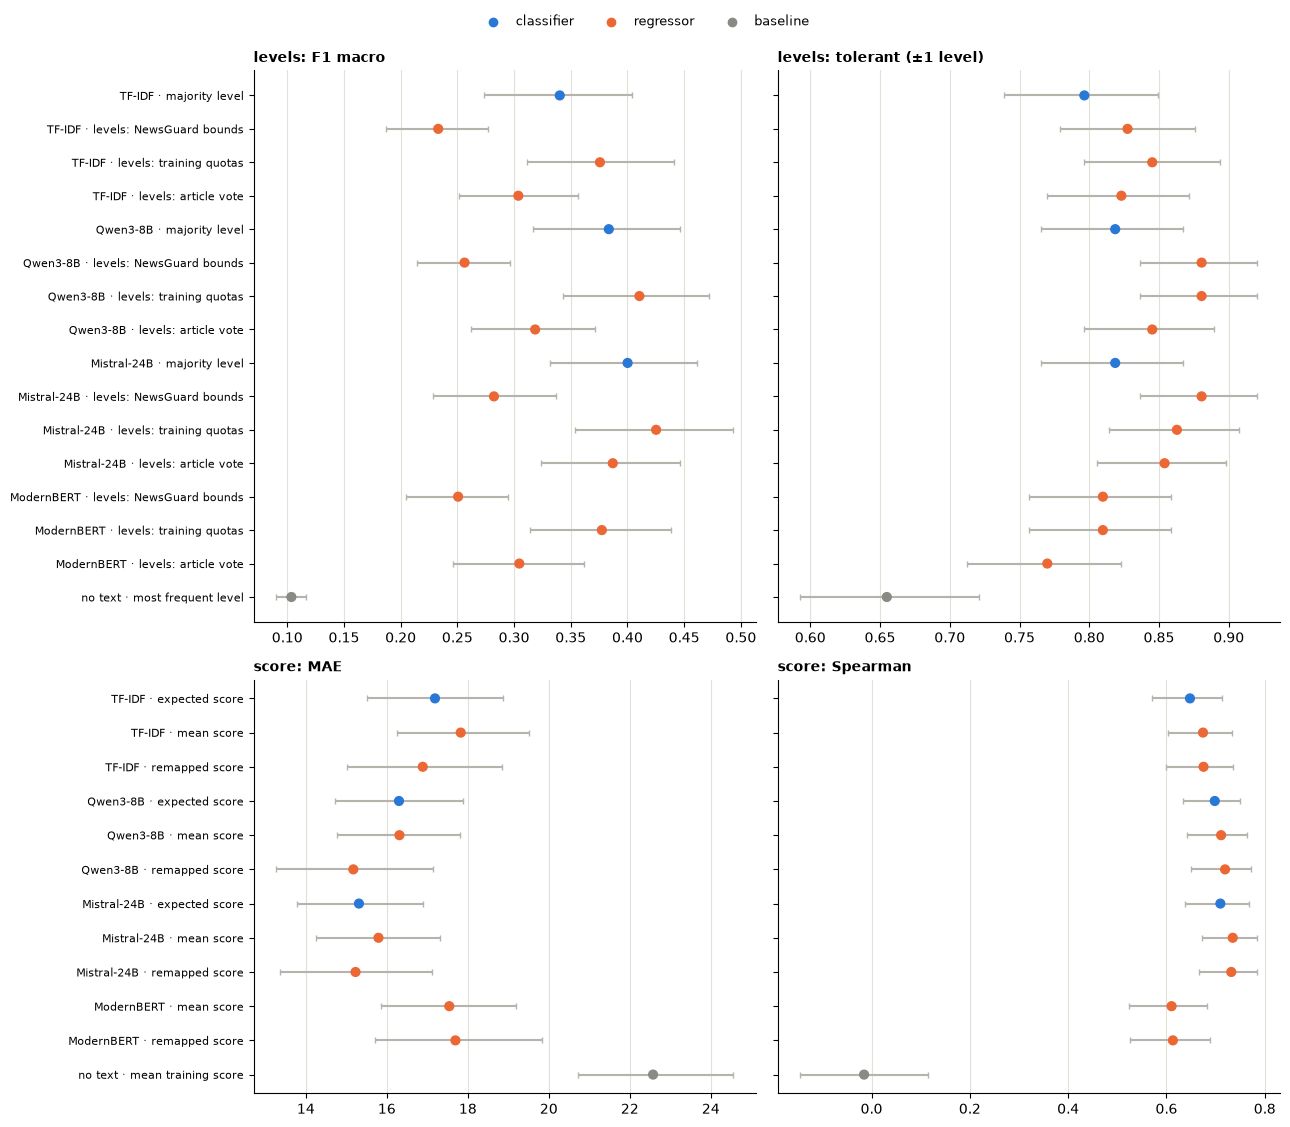

In [7]:
ROWS = [("levels", ["F1 macro", "tolerant (±1 level)"]), ("score", ["MAE", "Spearman"])]
COLOUR = {"classifier": "#2a78d6", "regressor": "#eb6834", "baseline": "#8a8983"}
n = [intervals[intervals.space == s].groupby(["model", "view"]).ngroups for s, _ in ROWS]
fig, axes = plt.subplots(2, 2, figsize=(13, 0.32 * sum(n) + 2), gridspec_kw={"height_ratios": n})
for r, (space, metrics) in enumerate(ROWS):
    for c, metric in enumerate(metrics):
        ax, d = axes[r, c], intervals[(intervals.space == space) & (intervals.metric == metric)].reset_index(drop=True)
        y = np.arange(len(d))
        ax.errorbar(d.value, y, xerr=[d.value - d.low, d.high - d.value], fmt="none", ecolor="#b5b3ab", lw=1.5, capsize=2)
        ax.scatter(d.value, y, s=40, c=[COLOUR[a] for a in d.approach], zorder=3)
        ax.set_yticks(y, [f"{m} · {v}" for m, v in zip(d.model, d.view)] if c == 0 else [""] * len(y), fontsize=8)
        ax.invert_yaxis(); ax.set_title(f"{space}: {metric}", fontsize=10, loc="left", fontweight="bold")
        ax.grid(axis="x", color="#e1e0d9"); ax.spines[["top", "right"]].set_visible(False)
for a, col in COLOUR.items():
    axes[0, 0].scatter([], [], c=col, label=a)
fig.legend(loc="upper center", ncol=3, fontsize=9, frameon=False, bbox_to_anchor=(0.5, 1.03))
plt.tight_layout(); plt.savefig(C.OUT / "results.png", dpi=150, bbox_inches="tight"); plt.show()

## In short

In [8]:
def best(space, metric, lower=False):
    d = all_metrics[(all_metrics.space == space) & (all_metrics.approach != "baseline")]
    r = d.loc[d[metric].idxmin() if lower else d[metric].idxmax()]
    base = all_metrics[(all_metrics.space == space) & (all_metrics.approach == "baseline")][metric].iloc[0]
    return f"- {space}, {metric}: {r.model} ({r.approach}, {r.view}) = {r[metric]:.3f}; without text {base:.3f}"


print("\n".join([best("levels", "F1 macro"), best("levels", "tolerant (±1 level)"), best("levels", "Spearman"),
                 best("score", "MAE", lower=True), best("score", "Spearman"), best("score", "within 10 points")]))
print(f"classifier/regressor differences that are not chance: {pairs['not chance'].sum()} of {len(pairs)}")

- levels, F1 macro: Mistral-24B (regressor, levels: training quotas) = 0.425; without text 0.104
- levels, tolerant (±1 level): Qwen3-8B (regressor, levels: NewsGuard bounds) = 0.881; without text 0.655
- levels, Spearman: Qwen3-8B (regressor, levels: training quotas) = 0.715; without text nan
- score, MAE: Qwen3-8B (regressor, remapped score) = 15.172; without text 22.575
- score, Spearman: Mistral-24B (regressor, mean score) = 0.735; without text -0.015
- score, within 10 points: Qwen3-8B (regressor, remapped score) = 0.478; without text 0.181
classifier/regressor differences that are not chance: 22 of 75
